# India Retail Sales and Profitability Analysis Using Python

Python Data Analysis Project

Dataset: https://www.kaggle.com/datasets/winstonbobby/indian-retail-sales

Tools: Python, Pandas, NumPy, Matplotlib, Seaborn

Domain: Retail & Business Analytics



### Problem Statement:

Analyze India retail transaction data to understand sales and profitability patterns across products, regions, customer segments, discounts, and shipping operations, and identify factors that influence business performance.

### Domain:

Retail & Business Analytics

Retail businesses can use data analysis to identify high-performing products, profitable regions and segments, discount patterns, sales trends, and areas of loss or lower profitability. The same analytical approach can be applied to different retail sectors such as grocery, clothing, electronics, and online retail.

### Dataset 

Dataset: https://www.kaggle.com/datasets/winstonbobby/indian-retail-sales

The dataset contains information related to orders, products, sales, profit, discounts, quantity, locations, customer segments, freight expenses, and shipping dates.

The combination of numerical and categorical variables makes the dataset suitable for data cleaning, exploratory data analysis, statistical analysis, aggregation, and visualization.


### Business Questions and Objectives

The analysis aims to answer the following business questions:

-How do sales and profit vary across different regions?

-Which product types generate the highest total and average profit?

-How is profit distributed across different product types and customer    segments?

-How do customer segments differ in terms of sales, profit, and profit margin?

-What relationships exist between sales, profit, quantity ordered, discount -offered, and freight expenses?

-How do these relationships differ between profitable orders and loss-making orders?

-Which states show unusually high or low profitability, and what factors contribute to the differences?

-How do sales and profit vary across combinations of region and customer segment?

-How does average profit vary across order priorities and customer segments?

-How do region, customer segment, and product type jointly affect total profit, and which combinations show the highest and lowest profit?

-How do freight expenses vary across regions, product types, and freight modes?

-How do sales and profit change over time, and which months show particularly high or low performance?

### Project Objective:

The overall objective is to transform retail transaction data into meaningful business insights that can help understand sales performance, profitability, product performance, geographical patterns, and operational factors.

#### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

#### Loading the Dataset

The dataset is loaded into a Pandas DataFrame for further analysis.

In [2]:
df = pd.read_excel("INDIA_RETAIL_DATA.xlsx")

# Display first 5 rows
df.head()

,Order Priority,Discount offered,Unit Price,Freight Expenses,Freight Mode,Segment,Product Type,Product Sub-Category,Product Container,State,City,Region,Country,Order Date,Ship Date,Profit,QtyOrdered,Sales
0,High,0.06,40.98,2.99,Regular Air,Personel Usage,Processed Meat,Bacon,Small Box,Madhya Pradesh,Rewa,West,India,2010-01-02,2010-01-04,-19.0992,3,124.81
1,High,0.05,155.06,7.07,Regular Air,Hotels / Hospitals,Processed Meat,Fresh Water Eel,Small Box,Meghalaya,Shillong,East,India,2010-01-02,2010-01-09,845.6640,8,1225.60
2,High,0.09,9.11,2.15,Express Air,Personel Usage,Processed Meat,Smoked Salmon,Wrap Bag,Maharashtra,Parbhani,West,India,2010-01-02,2010-01-04,20.2996,4,34.41
3,High,0.08,15.04,1.97,Regular Air,Personel Usage,Processed Meat,Smoked Salmon,Wrap Bag,Maharashtra,Parbhani,West,India,2010-01-02,2010-01-02,108.5163,11,157.27
4,High,0.03,4.26,1.20,Regular Air,Restaurant Chain,Processed Meat,Foie Gras,Wrap Bag,Uttar Pradesh,Ghaziabad,North,India,2010-01-03,2010-01-04,9.8200,29,122.23


#### Initial Overview

The dataset is examined to understand its structure, number of observations, column names, data types, and basic statistical characteristics.

In [5]:
#Number of rows and columns
df.shape

(2534, 18)

In [3]:
#Column names
df.columns

Index(['Order Priority', 'Discount offered', 'Unit Price', 'Freight Expenses',
       'Freight Mode', 'Segment', 'Product Type', 'Product Sub-Category',
       'Product Container', 'State', 'City', 'Region', 'Country', 'Order Date',
       'Ship Date', 'Profit', 'QtyOrdered', 'Sales'],
      dtype='object')

In [4]:
#Data types
df.dtypes

Order Priority                  object
Discount offered               float64
Unit Price                     float64
Freight Expenses               float64
Freight Mode                    object
Segment                         object
Product Type                    object
Product Sub-Category            object
Product Container               object
State                           object
City                            object
Region                          object
Country                         object
Order Date              datetime64[ns]
Ship Date               datetime64[ns]
Profit                         float64
QtyOrdered                       int64
Sales                          float64
dtype: object

In [5]:
#general information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2534 entries, 0 to 2533
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Order Priority        2534 non-null   object        
 1   Discount offered      2534 non-null   float64       
 2   Unit Price            2534 non-null   float64       
 3   Freight Expenses      2534 non-null   float64       
 4   Freight Mode          2534 non-null   object        
 5   Segment               2534 non-null   object        
 6   Product Type          2534 non-null   object        
 7   Product Sub-Category  2534 non-null   object        
 8   Product Container     2534 non-null   object        
 9   State                 2534 non-null   object        
 10  City                  2534 non-null   object        
 11  Region                2534 non-null   object        
 12  Country               2534 non-null   object        
 13  Order Date        

In [6]:
#Statistical summary
df.describe()

,Discount offered,Unit Price,Freight Expenses,Order Date,Ship Date,Profit,QtyOrdered,Sales
count,2534.000000,2534.000000,2534.000000,2534,2534,2534.000000,2534.000000,2534.000000
mean,0.049650,100.151405,12.222261,2012-03-14 20:56:26.898184704,2012-03-16 21:46:27.371744512,112.576198,14.238358,992.623717
min,0.000100,0.990000,0.490000,2010-01-02 00:00:00,2010-01-02 00:00:00,-14369.123580,1.000000,1.620000
25%,0.020000,6.480000,2.990000,2011-03-12 00:00:00,2011-03-13 00:00:00,-86.377263,5.000000,62.592500
50%,0.050000,20.890000,6.050000,2012-05-12 00:00:00,2012-05-14 00:00:00,1.231250,10.000000,191.160000
75%,0.080000,89.950000,12.980000,2013-03-26 00:00:00,2013-03-28 00:00:00,121.263000,17.000000,793.847500
max,0.100000,6783.020000,110.200000,2013-12-30 00:00:00,2013-12-30 00:00:00,16332.414000,170.000000,100119.160000
std,0.032171,357.023226,16.092475,NaN,NaN,1055.205939,16.014995,3147.339693


#### Initial Observation

-The dataset contains 2,594 rows and 18 columns.

-The columns have appropriate data types for analysis.

-The numerical data appears valid, with no obvious invalid values.

-The dataset contains useful information on sales, profit, products, discounts, locations, quantity, and shipping.


###  Data Pre-processing

#### Missing Values

Missing values are checked to determine whether any columns require treatment.


In [7]:
#Checking missing values
df.isnull().sum()

Order Priority          0
Discount offered        0
Unit Price              0
Freight Expenses        0
Freight Mode            0
Segment                 0
Product Type            0
Product Sub-Category    0
Product Container       0
State                   0
City                    0
Region                  0
Country                 0
Order Date              0
Ship Date               0
Profit                  0
QtyOrdered              0
Sales                   0
dtype: int64

Observation: The dataset contains no missing values, indicating that all 18 columns have complete data.

#### Duplicate Records

Duplicate records are checked to ensure that the same transaction is not counted more than once.

In [6]:
df.duplicated().sum()

np.int64(0)

Observation: No duplicate records were found in the dataset.

#### Creating Derived Columns

Derived columns are created from the existing data to generate additional useful information for analysis. These new variables help us understand profitability, cost, sales efficiency, discount levels, and shipping performance more clearly.

Shipping Days → to measure the time taken between order and shipment.

In [3]:
df['shipping_days']=(df['Ship Date']-df['Order Date']).dt.days

Profit Margin → to measure profit as a percentage of sales.

In [4]:
df['profit_margin']=(df['Profit']/df['Sales'])*100

Total Cost → to estimate the total cost associated with sales.

In [5]:
df['total_cost']=df['Sales']-df['Profit']

Sales Per Unit → to understand the average sales value generated per unit.

In [6]:
df['sales_per_unit']=df['Sales']/df['QtyOrdered']

Discount Percentage → to make the discount values easier to interpret.

In [7]:
df['discount_percentage']=df['Discount offered']*100

### Filtering and Aggregating Data

Filtered and summarized the dataset to prepare it for further analysis.

-Created two filtered datasets to identify profitable orders and loss-making orders based on the Profit column.

-Created summaries for total sales by region, total profit by product type, and sales and profit by customer segment.


In [8]:
# Orders with positive profit
profitable_orders = df[df['Profit'] > 0]
print("Profitable orders:", len(profitable_orders))

# Orders with negative profit (loss)
loss_orders = df[df['Profit'] < 0]
print("Loss-making orders:", len(loss_orders))

Profitable orders: 1286
Loss-making orders: 1248


#### Observation: 
The dataset contains 1,286 profitable orders and 1,248 loss-making orders, showing that the number of profitable and loss-making orders is relatively close.

In [54]:
# Total sales by region
region_sales = df.groupby('Region')['Sales'].sum()
region_sales

Region
East     228376.23
North    956630.55
South    388339.53
West     941962.19
Name: Sales, dtype: float64

In [55]:
# Total profit by product type
product_profit = df.groupby('Product Type')['Profit'].sum()
product_profit

Product Type
Canned Foods      102821.224948
Preserved Food     65187.091711
Processed Meat    117259.768464
Name: Profit, dtype: float64

In [56]:
# Sales and profit by customer segment
segment_performance = df.groupby('Segment')[['Sales', 'Profit']].sum()
segment_performance

,Sales,Profit
Segment,,
Hotels / Hospitals,841291.78,78918.374864
Personel Usage,667768.32,43027.339246
Restaurant Chain,592401.83,79915.194660
Stand Alone Restaurants,413846.57,83407.176352


## Exploratory Data Analysis

The dataset will be explored using descriptive and exploratory analysis to identify patterns, trends, and relationships related to the business questions.

The analysis will include univariate, bivariate, and multivariate analysis, along with groupby operations, pivot tables, correlation analysis, and statistical summaries.


#### Univariate Analysis

Both numerical and categorical variables will be examined to understand the structure of the retail data.

In [18]:
#Numerical Variables
df.describe()

,Discount offered,Unit Price,Freight Expenses,Order Date,Ship Date,Profit,QtyOrdered,Sales,shipping_days,profit_margin,total_cost,sales_per_unit,discount_percentage
count,2534.000000,2534.000000,2534.000000,2534,2534,2534.000000,2534.000000,2534.000000,2534.000000,2534.000000,2534.000000,2534.000000,2534.000000
mean,0.049650,100.151405,12.222261,2012-03-14 20:56:26.898184704,2012-03-16 21:46:27.371744512,112.576198,14.238358,992.623717,2.034728,63.277610,880.047520,96.067323,4.965020
min,0.000100,0.990000,0.490000,2010-01-02 00:00:00,2010-01-02 00:00:00,-14369.123580,1.000000,1.620000,0.000000,-17672.025065,-12174.034000,1.114000,0.010000
25%,0.020000,6.480000,2.990000,2011-03-12 00:00:00,2011-03-13 00:00:00,-86.377263,5.000000,62.592500,1.000000,-55.816135,65.145350,6.752542,2.000000
50%,0.050000,20.890000,6.050000,2012-05-12 00:00:00,2012-05-14 00:00:00,1.231250,10.000000,191.160000,2.000000,0.563616,222.422000,20.329000,5.000000
75%,0.080000,89.950000,12.980000,2013-03-26 00:00:00,2013-03-28 00:00:00,121.263000,17.000000,793.847500,2.000000,45.308138,737.550700,86.724246,8.000000
max,0.100000,6783.020000,110.200000,2013-12-30 00:00:00,2013-12-30 00:00:00,16332.414000,170.000000,100119.160000,92.000000,99998.303030,92621.610000,7122.170000,10.000000
std,0.032171,357.023226,16.092475,NaN,NaN,1055.205939,16.014995,3147.339693,2.657955,2708.658845,3037.011749,339.953659,3.217128


In [21]:
#categorical variables
df.describe(include='O')

,Order Priority,Freight Mode,Segment,Product Type,Product Sub-Category,Product Container,State,City,Region,Country
count,2534,2534,2534,2534,2534,2534,2534,2534,2534,2534
unique,5,3,4,3,17,7,22,339,4,1
top,High,Regular Air,Hotels / Hospitals,Processed Meat,Smoked Salmon,Small Box,Uttar Pradesh,Rewa,North,India
freq,1624,1892,869,1407,399,1296,473,196,890,2534


In [22]:
df['Region'].value_counts()

Region
North    890
West     811
South    542
East     291
Name: count, dtype: int64

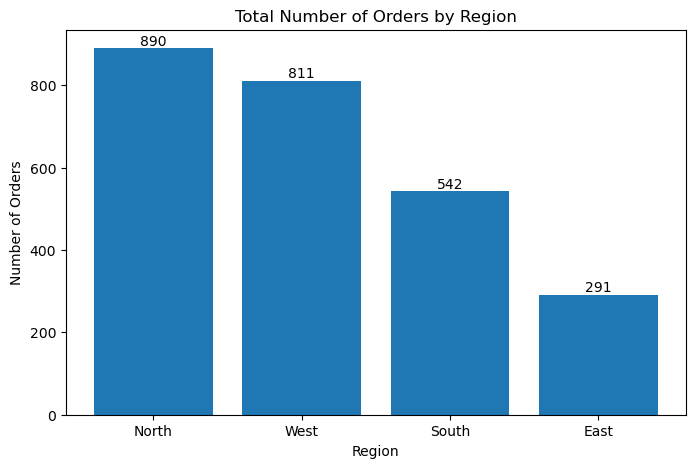

In [25]:
region_orders = df['Region'].value_counts()

plt.figure(figsize=(8,5))

bars = plt.bar(
    region_orders.index,
    region_orders.values
)

plt.title('Total Number of Orders by Region')
plt.xlabel('Region')
plt.ylabel('Number of Orders')

plt.bar_label(bars)

plt.show()

In [23]:
df['Segment'].value_counts()

Segment
Hotels / Hospitals         869
Restaurant Chain           625
Personel Usage             591
Stand Alone Restaurants    449
Name: count, dtype: int64

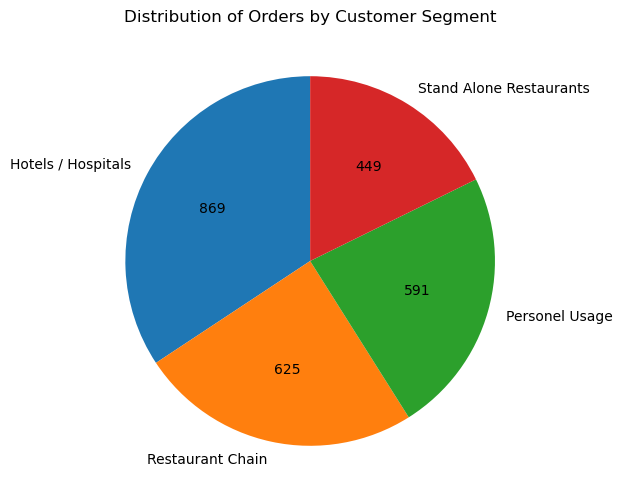

In [27]:
segment_orders = df['Segment'].value_counts()

plt.figure(figsize=(8,6))

plt.pie(
    segment_orders.values,
    labels=segment_orders.index,
     autopct=lambda p: f'{p * sum(segment_orders.values) / 100:.0f}',
    startangle=90
)

plt.title('Distribution of Orders by Customer Segment')

plt.show()

### Bivariate Analysis

Finding the relationship between two variables.

##### Sales vs Profit

In [24]:
df[['Sales', 'Profit']].corr()

,Sales,Profit
Sales,1.000000,0.270358
Profit,0.270358,1.000000


Observation:
The correlation between Sales and Profit is **0.27**, indicating a weak positive relationship between the two variables. This suggests that higher sales are generally associated with higher profit, but the relationship is not strong. Therefore, sales alone may not explain variations in profit, and other factors such as discounts, costs, and product or regional performance may also influence profitability.


##### Discount vs Profit

In [25]:
df[['Discount offered', 'Profit']].corr()

,Discount offered,Profit
Discount offered,1.000000,-0.031247
Profit,-0.031247,1.000000


Observation: Discount and Profit have a very weak negative relationship with a correlation of -0.03. This means there is almost no relationship between discount and profit in this dataset.

##### Profit vs Quantity

In [57]:
df[['Profit', 'QtyOrdered']].corr()

,Profit,QtyOrdered
Profit,1.000000,0.105965
QtyOrdered,0.105965,1.000000


Observation: Sales and Quantity Ordered have a weak positive relationship with a correlation of 0.10. This means that higher quantities ordered are generally associated with higher Profit.

#### Bivariate Relationships with Sales

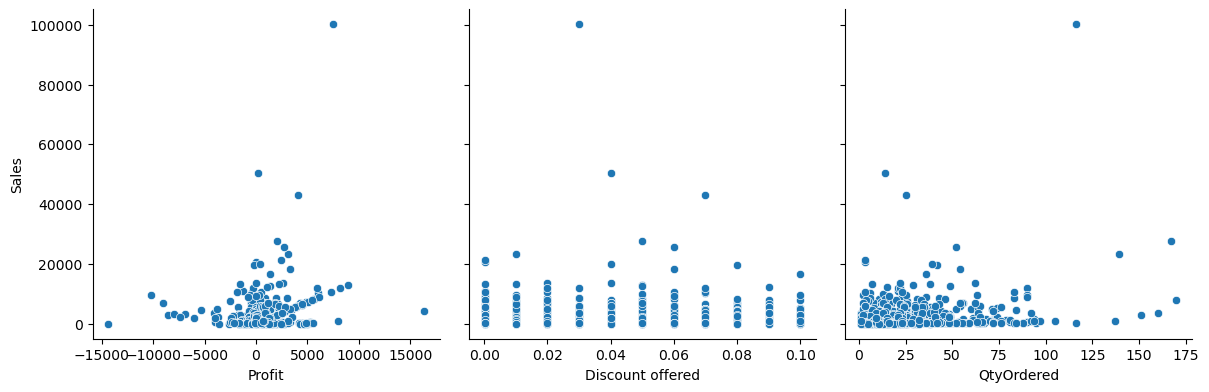

In [35]:
bivariate_data = df[
    ['Sales', 'Profit', 'Discount offered', 'QtyOrdered']
]

g = sns.PairGrid(
    bivariate_data,
    x_vars=['Profit', 'Discount offered', 'QtyOrdered'],
    y_vars=['Sales'],
    height=4
)

g.map(sns.scatterplot)
plt.show()

This PairGrid shows the relationship between Sales and three numerical variables: Profit, Discount Offered, and Quantity Ordered.

#### Bivariate Relationships with Profit

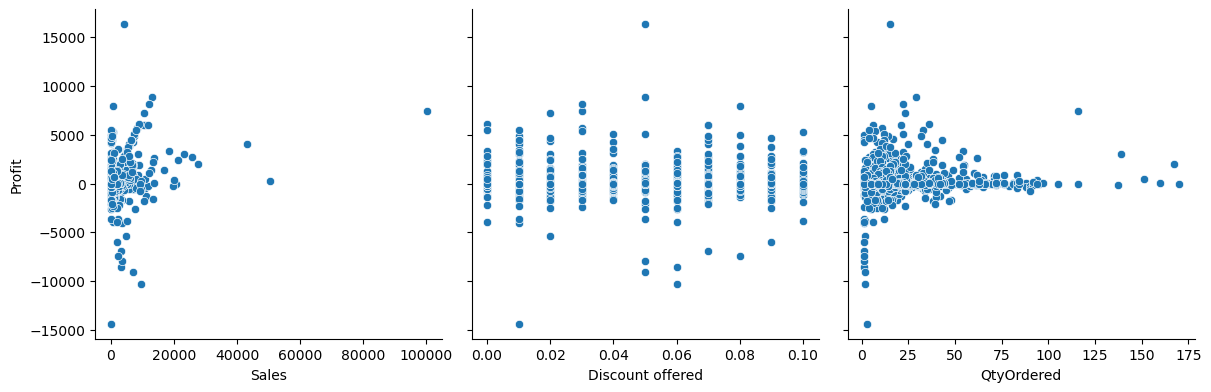

In [34]:
bivariate_data = df[
    ['Sales', 'Profit', 'Discount offered', 'QtyOrdered']
]

g = sns.PairGrid(
    bivariate_data,
    x_vars=['Sales', 'Discount offered', 'QtyOrdered'],
    y_vars=['Profit'],
    height=4
)

g.map(sns.scatterplot)
plt.show()

This PairGrid shows the relationship between Profit and three numerical variables: Sales, Discount Offered, and Quantity Ordered.

Higher sales are generally associated with higher profit, but the relationship is not strong. Therefore, sales alone may not explain variations in profit, and other factors such as discounts, costs, product,quantity or regional performance may also influence profitability.

#### Sales vs Profit - Profitable Orders

In [32]:
profitable_orders[['Sales','Profit']].corr()

,Sales,Profit
Sales,1.000000,0.410356
Profit,0.410356,1.000000


Observation: Sales and Profit have a moderate positive relationship with a correlation of 0.41 among profitable orders. This means that higher sales are generally associated with higher profit.

In [45]:
profitable_orders[['QtyOrdered','Profit']].corr()

,QtyOrdered,Profit
QtyOrdered,1.000000,0.093035
Profit,0.093035,1.000000


Observation: Quantity Ordered and Profit have a very weak positive relationship with a correlation of 0.09 among profitable orders. This means that quantity ordered has very little relationship with profit, so this does not mean that increasing quantity will directly increase profit.

In [54]:
profitable_orders[['Discount offered','Profit']].corr()

,Discount offered,Profit
Discount offered,1.000000,-0.056534
Profit,-0.056534,1.000000


In [55]:
profitable_orders[['Freight Expenses','Profit']].corr()

,Freight Expenses,Profit
Freight Expenses,1.000000,0.213263
Profit,0.213263,1.000000


Conclusion: 
In the Profitable orders, Sales has the strongest relationship with Profit among the variables, while Quantity Ordered, Discount, and Freight Expenses have weak or very weak relationships with Profit.

#### Bivariate Relationships with Profit - Profitable Orders

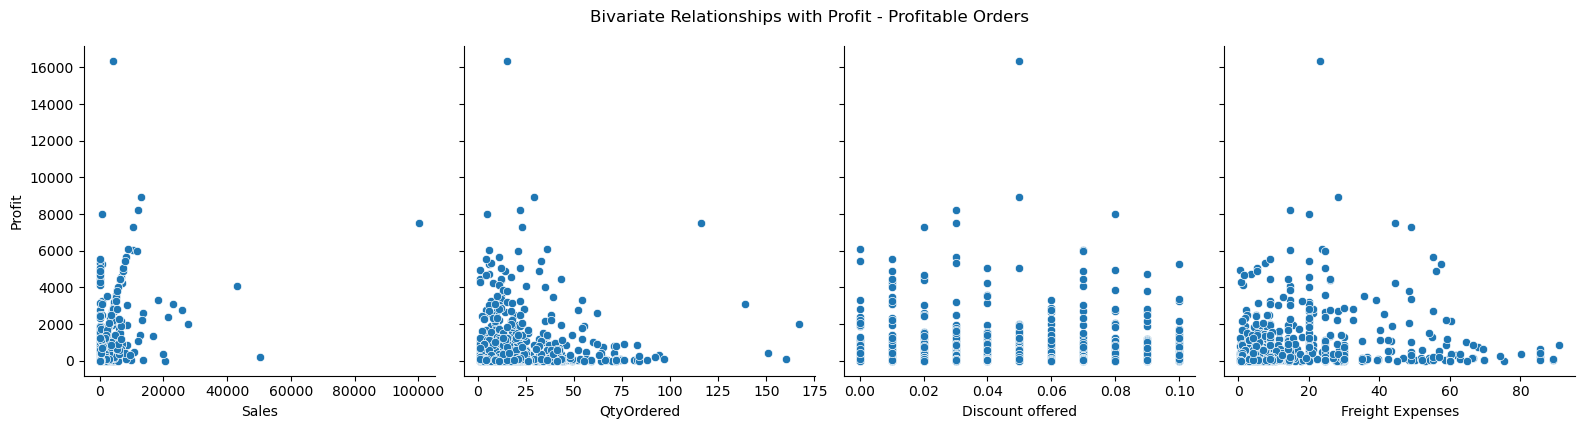

In [36]:
profitable_data = profitable_orders[
    ['Sales', 'Profit', 'QtyOrdered',
     'Discount offered', 'Freight Expenses']
]

g = sns.PairGrid(
    profitable_data,
    x_vars=[
        'Sales',
        'QtyOrdered',
        'Discount offered',
        'Freight Expenses'
    ],
    y_vars=['Profit'],
    height=4
)


g.map(sns.scatterplot)

g.fig.suptitle(
    'Bivariate Relationships with Profit - Profitable Orders',
    y=1.05
)

plt.show()

Conclusion: 
In the Profitable orders, Sales has the strongest relationship with Profit among the variables, while Quantity Ordered, Discount, and Freight Expenses have weak or very weak relationships with Profit.

#### Sales vs Profit - Loss Orders

In [48]:
loss_orders[['Profit','Sales']].corr()

,Profit,Sales
Profit,1.000000,-0.262512
Sales,-0.262512,1.000000


In [51]:
loss_orders[['QtyOrdered','Sales']].corr()

,QtyOrdered,Sales
QtyOrdered,1.000000,0.305907
Sales,0.305907,1.000000


In [52]:
loss_orders[['Freight Expenses','Sales']].corr()

,Freight Expenses,Sales
Freight Expenses,1.000000,0.381595
Sales,0.381595,1.000000


In [53]:
loss_orders[['Freight Expenses','Profit']].corr()

,Freight Expenses,Profit
Freight Expenses,1.000000,-0.158276
Profit,-0.158276,1.000000


#### Profit Relationships Among Loss-Making Orders

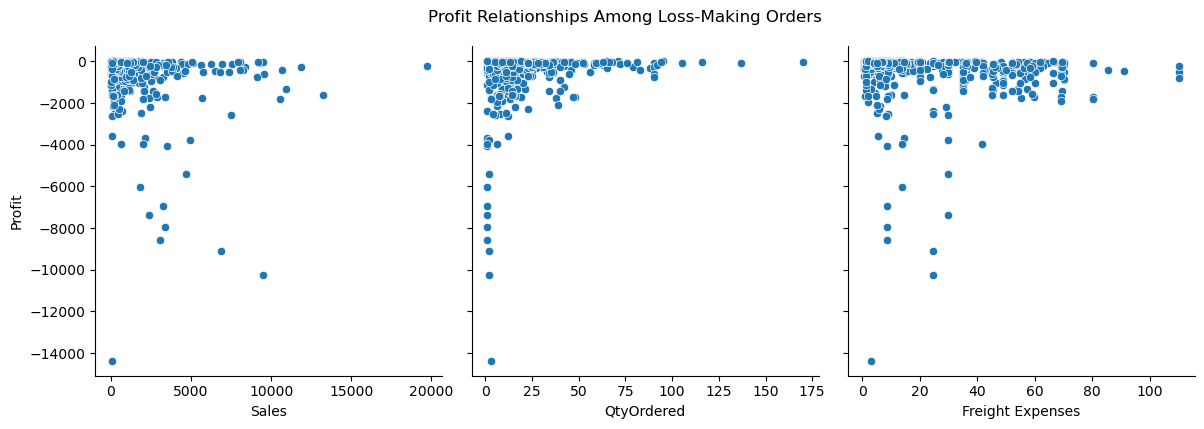

In [39]:
loss_profit_data = loss_orders[
    ['Profit', 'Sales', 'QtyOrdered', 'Freight Expenses']
]

g = sns.PairGrid(
    loss_profit_data,
    x_vars=['Sales', 'QtyOrdered', 'Freight Expenses'],
    y_vars=['Profit'],
    height=4
)

g.map(sns.scatterplot)

g.fig.suptitle(
    'Profit Relationships Among Loss-Making Orders',
    y=1.05
)

plt.show()

#### Sales Relationships Among Loss-Making Orders

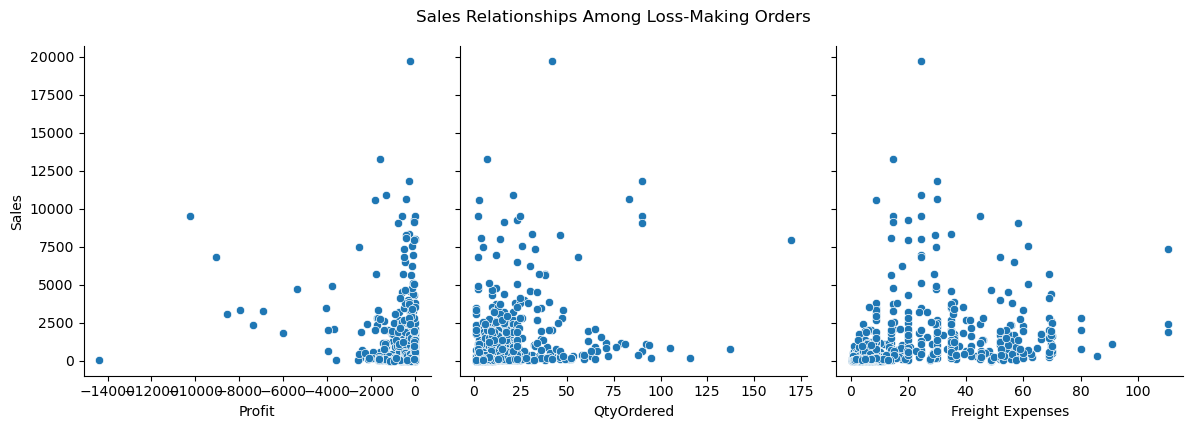

In [40]:
loss_sales_data = loss_orders[
    ['Sales', 'Profit', 'QtyOrdered', 'Freight Expenses']
]

g = sns.PairGrid(
    loss_sales_data,
    x_vars=['Profit', 'QtyOrdered', 'Freight Expenses'],
    y_vars=['Sales'],
    height=4
)

g.map(sns.scatterplot)

g.fig.suptitle(
    'Sales Relationships Among Loss-Making Orders',
    y=1.05
)

plt.show()

Observation: In the loss-making orders, Sales have a weak negative relationship with Profit. Freight Expenses have a positive relationship with Sales and a weak negative relationship with Profit. This suggests that higher-sales orders tend to have higher freight expenses, while higher freight expenses are also associated with slightly lower profit.

### GroupBy Analysis

##### 1)Sales by Region

In [9]:
region_sales = df.groupby('Region',as_index=False)['Sales'].sum().sort_values('Sales', ascending=False).reset_index(drop=True)

region_sales

,Region,Sales
0,North,956630.55
1,West,941962.19
2,South,388339.53
3,East,228376.23


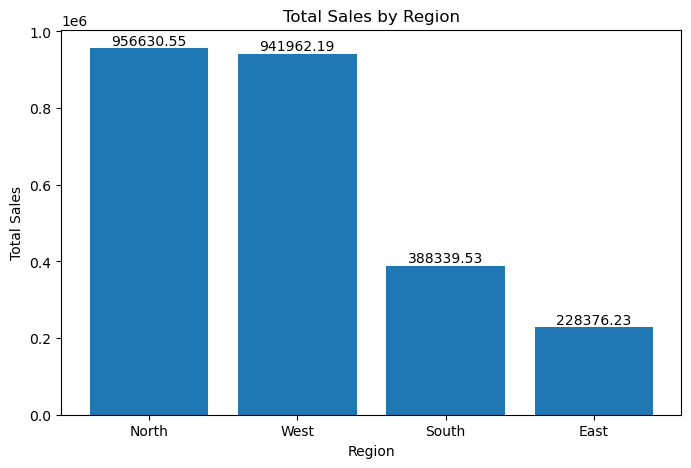

In [45]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    region_sales['Region'],
    region_sales['Sales']
)

plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')

plt.bar_label(bars, fmt='%.2f')

plt.show()

Observation: The North region has the highest total sales (956,630.55), followed closely by the West region. The East region has the lowest total sales (228,376.23).

##### 2)Total Profit by Product Type

In [47]:
product_profit = df.groupby('Product Type', as_index=False)['Profit'].sum().sort_values('Profit', ascending=False)

product_profit

,Product Type,Profit
2,Processed Meat,117259.768464
0,Canned Foods,102821.224948
1,Preserved Food,65187.091711


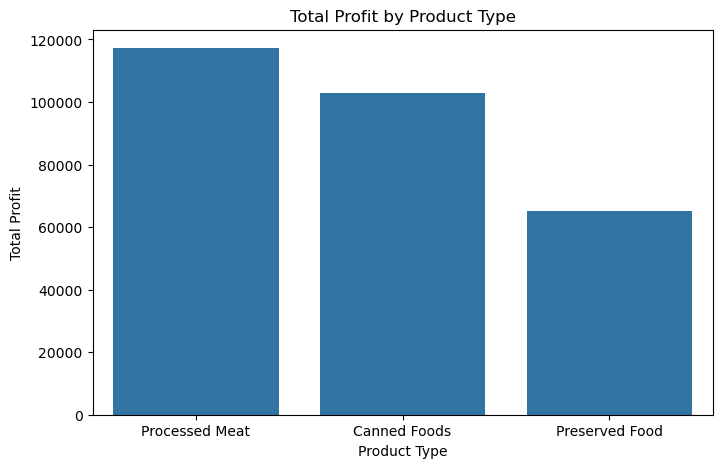

In [48]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=product_profit,
    x='Product Type',
    y='Profit'
)

plt.title('Total Profit by Product Type')
plt.xlabel('Product Type')
plt.ylabel('Total Profit')

plt.show()

Observation: Processed Meat has the highest total profit (117,259.77), followed by Canned Foods (102,821.22). Preserved Food has the lowest total profit (65,187.09).

##### 3)Average profit by Product Type

In [49]:
Avg_product_profit = df.groupby('Product Type', as_index=False)['Profit'].mean().sort_values('Profit', ascending=False)

Avg_product_profit

,Product Type,Profit
0,Canned Foods,162.949643
1,Preserved Food,131.425588
2,Processed Meat,83.340276


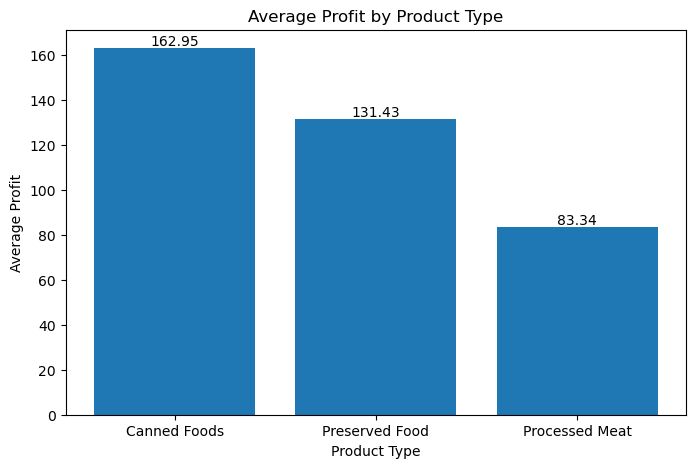

In [51]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    Avg_product_profit['Product Type'],
    Avg_product_profit['Profit']
)

plt.title('Average Profit by Product Type')
plt.xlabel('Product Type')
plt.ylabel('Average Profit')

plt.bar_label(bars, fmt='%.2f')

plt.show()

Observation: Canned Foods has the highest average profit per order at 162.95, followed by Preserved Food at 131.43. Processed Meat has the lowest average profit per order at 83.34. 
-Processed Meat has the highest total profit, Canned Foods has the highest average profit per order.

#### Profit Distribution by Product Type

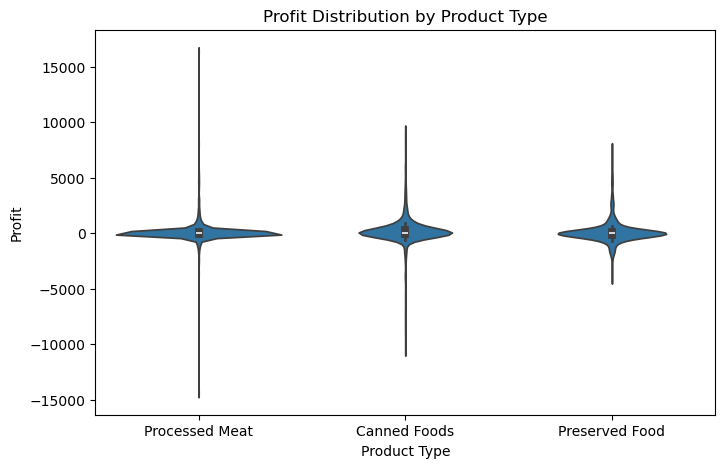

In [90]:
plt.figure(figsize=(8,5))
sns.violinplot(data=df, x='Product Type', y='Profit')
plt.title('Profit Distribution by Product Type')
plt.xlabel('Product Type')
plt.ylabel('Profit')
plt.show()

The violin plot shows that the profit distributions for all product types are relatively concentrated around zero, as indicated by the wider sections of the violins near zero. This means that many individual orders have profit values close to zero.

#### Segment Performance

##### 4) Sales and Profit by Segment

In [53]:
segment_performance = df.groupby(
    'Segment', as_index=False
)[['Sales', 'Profit']].sum()

segment_performance

,Segment,Sales,Profit
0,Hotels / Hospitals,841291.78,78918.374864
1,Personel Usage,667768.32,43027.339246
2,Restaurant Chain,592401.83,79915.194660
3,Stand Alone Restaurants,413846.57,83407.176352


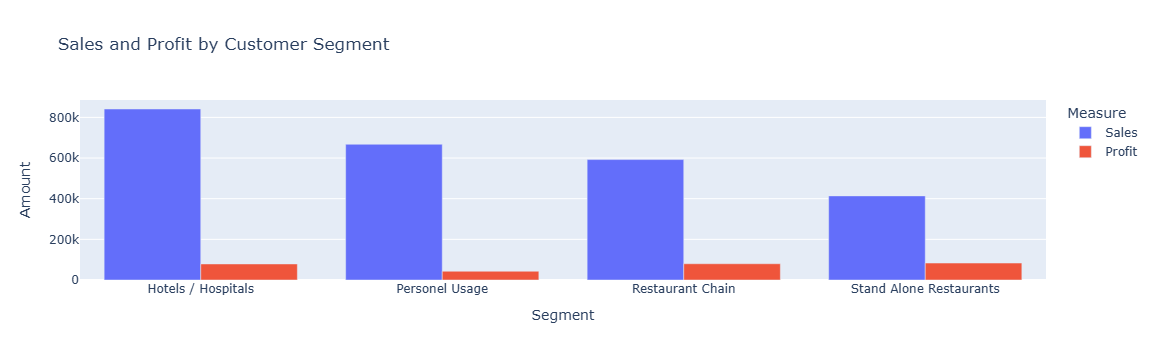

In [54]:
fig = px.bar(
    segment_performance,
    x='Segment',
    y=['Sales', 'Profit'],
    barmode='group',
    title='Sales and Profit by Customer Segment',
    labels={
        'value': 'Amount',
        'variable': 'Measure'
    }
)

fig.show()

###### Finding the highest performing segment

In [56]:
segment_performance['Profit_Margin'] = (
    segment_performance['Profit'] /
    segment_performance['Sales']
) * 100

segment_performance.sort_values(
    'Profit_Margin', ascending=False
).reset_index(drop=True)

,Segment,Sales,Profit,Profit_Margin
0,Stand Alone Restaurants,413846.57,83407.176352,20.154130
1,Restaurant Chain,592401.83,79915.194660,13.490032
2,Hotels / Hospitals,841291.78,78918.374864,9.380619
3,Personel Usage,667768.32,43027.339246,6.443453


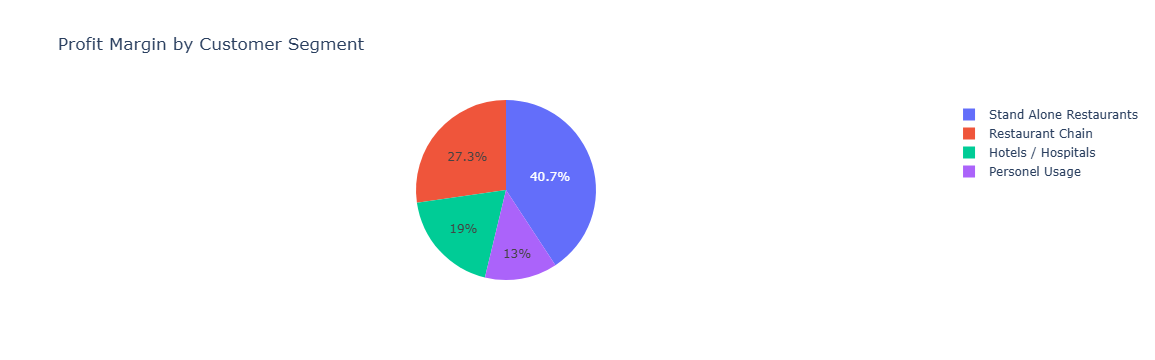

In [57]:
fig = px.pie(
    segment_performance,
    names='Segment',
    values='Profit_Margin',
    title='Profit Margin by Customer Segment'
)

fig.show()

Observation: Stand Alone Restaurants have the highest profit margin, followed by Restaurant Chain and Hotels / Hospitals. Personel Usage has the lowest profit margin. 
-Stand Alone Restaurants generate the highest profit relative to their sales.

#### Region Performance

##### Sales and Profit by Region

In [58]:
region_performance = df.groupby(
    'Region', as_index=False
)[['Sales','Profit']].sum()


region_performance['Profit_Margin'] = (
    region_performance['Profit'] /
    region_performance['Sales']
) * 100

region_performance.sort_values(
    'Profit_Margin', ascending=False
).reset_index(drop=True)

,Region,Sales,Profit,Profit_Margin
0,South,388339.53,55817.792036,14.373451
1,East,228376.23,31567.429831,13.822555
2,North,956630.55,118198.711616,12.355732
3,West,941962.19,79684.151639,8.459379


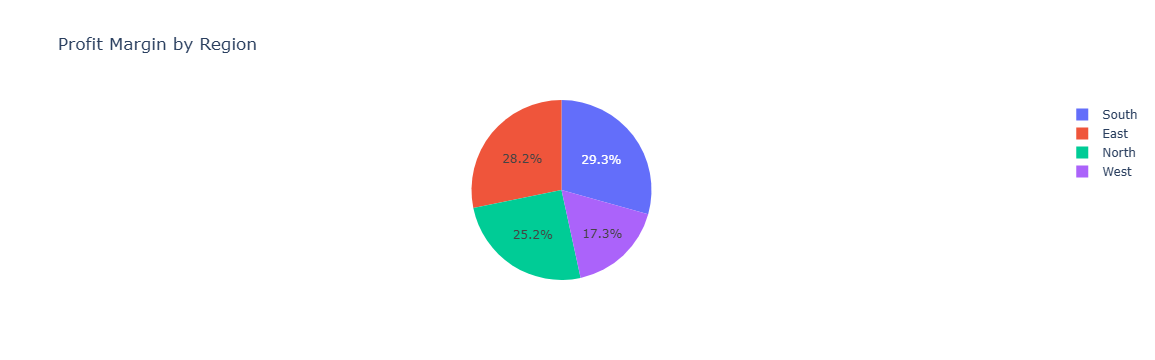

In [61]:
fig = px.pie(
    region_performance,
    names='Region',
    values='Profit_Margin',
    title='Profit Margin by Region'
)

fig.show()

Observation: South region has the highest profit margin at, followed by East region and North region. West region has the lowest profit margin. 


#### State performance 

In [62]:
state_performance=df.groupby('State', as_index=False)[['Sales','Profit']].sum()
state_performance['Profit_Margin'] = (
    state_performance['Profit'] /
    state_performance['Sales']
) * 100

state_performance.sort_values(
    'Profit_Margin', ascending=False
).reset_index(drop=True)

,State,Sales,Profit,Profit_Margin
0,Kerala,44739.60,17324.934886,38.723938
1,Karnataka,60847.69,21807.616120,35.839678
2,Jammu And Kashmir,14242.32,3816.512400,26.796985
3,Maharashtra,136383.49,32250.748800,23.647106
4,Punjab,35762.31,7457.981336,20.854305
5,West Bengal,136218.27,25402.282748,18.648220
6,Gujarat,71625.96,12889.125504,17.995047
7,Chhattisgarh,21105.61,3717.423330,17.613437
8,Uttar Pradesh,641059.04,104213.124465,16.256400
9,Bihar,160228.30,23672.749109,14.774387


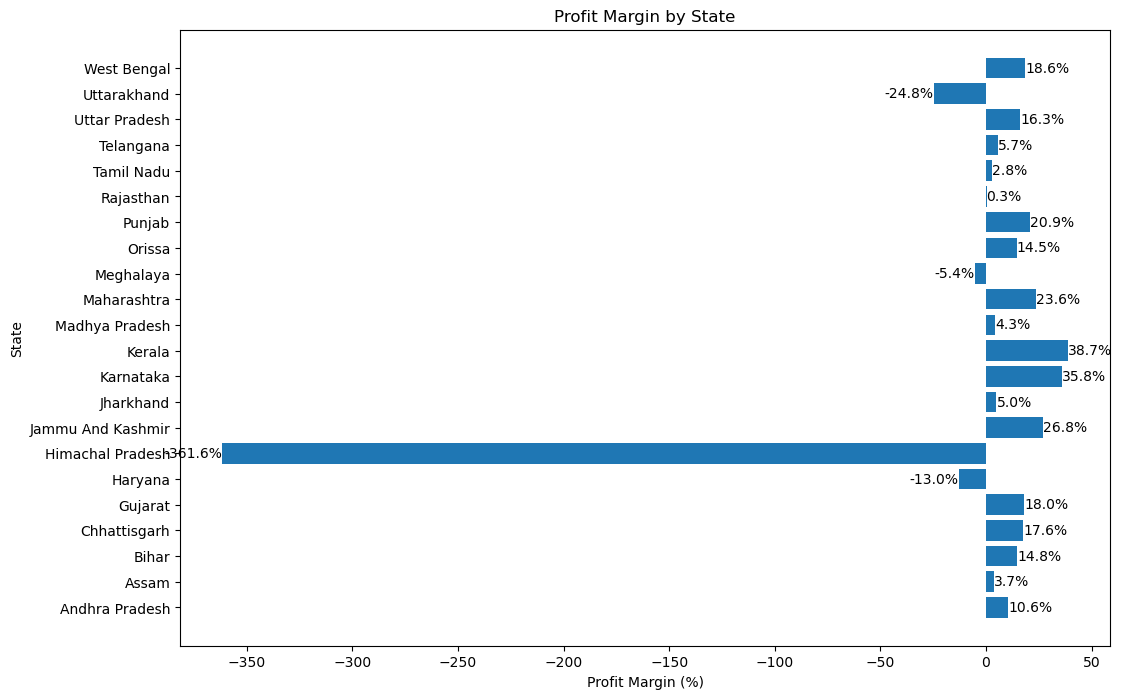

In [63]:
plt.figure(figsize=(12,8))

bars = plt.barh(
    state_performance['State'],
    state_performance['Profit_Margin']
)

plt.title('Profit Margin by State')
plt.xlabel('Profit Margin (%)')
plt.ylabel('State')

plt.bar_label(bars, fmt='%.1f%%')

plt.show()

##### Identify the lowest-profit-margin state

In [13]:
lowest_margin_state = state_performance.loc[
    state_performance['Profit_Margin'].idxmin()
]

lowest_margin_state

State            Himachal Pradesh
Sales                     3674.67
Profit               -13288.46058
Profit_Margin         -361.623236
Name: 6, dtype: object

###### Find the products sold in that state

In [14]:
low_state = lowest_margin_state['State']

state_data = df[df['State'] == low_state]

state_data

,Order Priority,Discount offered,Unit Price,Freight Expenses,Freight Mode,Segment,Product Type,Product Sub-Category,Product Container,State,...,Order Date,Ship Date,Profit,QtyOrdered,Sales,shipping_days,profit_margin,total_cost,sales_per_unit,discount_percentage
25,High,0.0800,8.09,7.96,Express Air,Restaurant Chain,Preserved Food,Marmalade,Small Box,Himachal Pradesh,...,2010-01-15,2010-01-16,15.98400,6,48.25,1,33.127461,32.26600,8.041667,8.00
88,Critical,0.0900,35.99,5.99,Regular Air,Restaurant Chain,Canned Foods,Quail Eggs,Wrap Bag,Himachal Pradesh,...,2010-02-26,2010-02-27,114.31650,5,151.60,1,75.406662,37.28350,30.320000,9.00
444,High,0.0200,25.99,5.37,Regular Air,Restaurant Chain,Processed Meat,Foie Gras,Small Box,Himachal Pradesh,...,2010-10-15,2010-10-17,-88.15800,9,243.24,2,-36.243217,331.39800,27.026667,2.00
524,High,0.0900,2.60,2.40,Regular Air,Restaurant Chain,Processed Meat,Foie Gras,Wrap Bag,Himachal Pradesh,...,2010-12-17,2010-12-19,1107.40800,12,31.73,2,3490.097699,-1075.67800,2.644167,9.00
1283,High,0.0100,24.95,2.99,Regular Air,Restaurant Chain,Processed Meat,Bacon,Small Box,Himachal Pradesh,...,2012-05-21,2012-05-21,-14369.12358,3,81.31,0,-17672.025065,14450.43358,27.103333,1.00
1321,High,0.0800,4.98,4.72,Regular Air,Restaurant Chain,Processed Meat,Smoked Salmon,Small Box,Himachal Pradesh,...,2012-06-16,2012-06-17,167.84400,7,34.55,1,485.800289,-133.29400,4.935714,8.00
1913,High,0.0200,4.28,5.17,Express Air,Restaurant Chain,Processed Meat,Smoked Salmon,Small Box,Himachal Pradesh,...,2013-03-28,2013-03-30,-93.32400,3,16.71,2,-558.491921,110.03400,5.570000,2.00
1914,Not Specified,0.0001,35.99,3.30,Regular Air,Restaurant Chain,Canned Foods,Quail Eggs,Small Pack,Himachal Pradesh,...,2013-03-28,2013-03-30,-158.64800,11,360.06,2,-44.061545,518.70800,32.732727,0.01
2136,Critical,0.0600,179.99,13.99,Express Air,Stand Alone Restaurants,Canned Foods,Quail Eggs,Medium Box,Himachal Pradesh,...,2013-07-09,2013-07-11,-23.40800,16,2469.01,2,-0.948072,2492.41800,154.313125,6.00
2333,High,0.0600,7.10,6.05,Regular Air,Stand Alone Restaurants,Processed Meat,Bacon,Small Box,Himachal Pradesh,...,2013-10-04,2013-10-04,-51.30150,9,63.27,0,-81.083452,114.57150,7.030000,6.00


###### Calculate profit margin for each product type

In [15]:
state_product = state_data.groupby(
    'Product Type', as_index=False
)[['Sales', 'Profit']].sum()

state_product['Profit_Margin'] = (
    state_product['Profit'] /
    state_product['Sales']
) * 100

state_product.sort_values(
    'Sales', ascending=False
).reset_index(drop=True)

,Product Type,Sales,Profit,Profit_Margin
0,Canned Foods,2980.67,-67.73950,-2.272627
1,Processed Meat,470.81,-13326.65508,-2830.580294
2,Preserved Food,223.19,105.93400,47.463596


-For processed meat sales are only 470.81, it has a very large loss of -13,326.66.

Check how many Processed Meat orders there are

In [42]:
processed_meat = state_data[
    state_data['Product Type'] == 'Processed Meat'
]

processed_meat.shape[0]

6

In [44]:
processed_meat[
    ['Sales', 'Profit', 'QtyOrdered',
     'Discount offered', 'Freight Expenses']
]

,Sales,Profit,QtyOrdered,Discount offered,Freight Expenses
444,243.24,-88.15800,9,0.02,5.37
524,31.73,1107.40800,12,0.09,2.40
1283,81.31,-14369.12358,3,0.01,2.99
1321,34.55,167.84400,7,0.08,4.72
1913,16.71,-93.32400,3,0.02,5.17
2333,63.27,-51.30150,9,0.06,6.05


In [45]:
df.loc[1283]

Order Priority                         High
Discount offered                       0.01
Unit Price                            24.95
Freight Expenses                       2.99
Freight Mode                    Regular Air
Segment                    Restaurant Chain
Product Type                 Processed Meat
Product Sub-Category                  Bacon
Product Container                 Small Box
State                      Himachal Pradesh
City                               Hamirpur
Region                                North
Country                               India
Order Date              2012-05-21 00:00:00
Ship Date               2012-05-21 00:00:00
Profit                         -14369.12358
QtyOrdered                                3
Sales                                 81.31
shipping_days                             0
profit_margin                 -17672.025065
total_cost                      14450.43358
sales_per_unit                    27.103333
discount_percentage             

##### Distribution of Profit Margin Across States

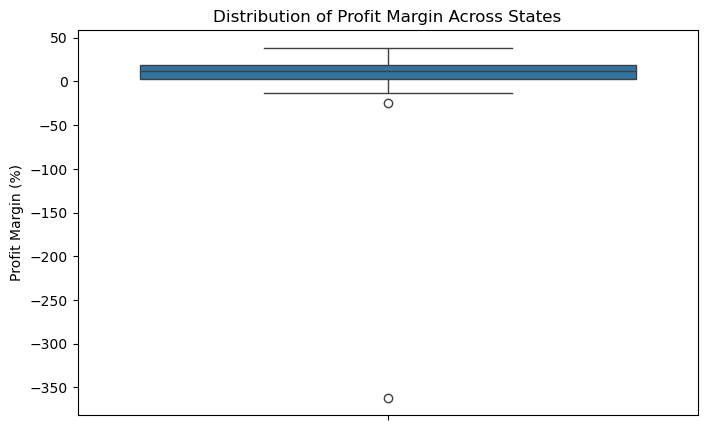

In [64]:
plt.figure(figsize=(8,5))

sns.boxplot(
    y=state_performance['Profit_Margin']
)

plt.title('Distribution of Profit Margin Across States')
plt.ylabel('Profit Margin (%)')

plt.show()

##### Outlier Identification
Himachal Pradesh showed the lowest calculated profit margin in the dataset. Further investigation revealed that this result was strongly influenced by an unusually large loss from a single Processed Meat order.
The box plot was used to identify unusually high or low state-level profit margins. A potential outlier was observed, which was further investigated at the state and order level.

#### Pivot Table Analysis

Sales and profit are compared across regions and customer segments to identify differences in performance between these groups.

##### Region × Segment — Sales

In [67]:
pivot_sales = pd.pivot_table(
    df,
    values='Sales',
    index='Region',
    columns='Segment',
    aggfunc='sum'
)

pivot_sales


Segment,Hotels / Hospitals,Personel Usage,Restaurant Chain,Stand Alone Restaurants
Region,,,,
East,71076.57,48166.65,35474.35,73658.66
North,204420.44,310442.22,272994.17,168773.72
South,154090.57,98803.67,77279.51,58165.78
West,411704.20,210355.78,206653.80,113248.41


##### Heatmap

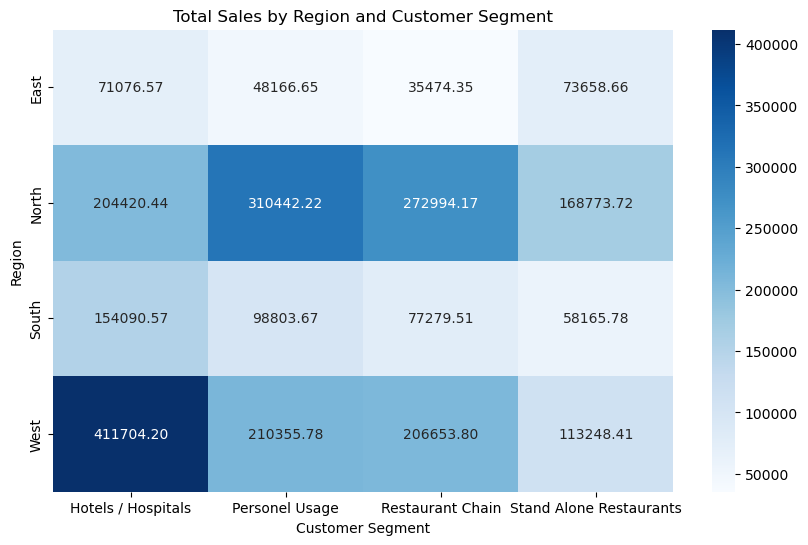

In [68]:
plt.figure(figsize=(10,6))

sns.heatmap(
    pivot_sales,
    annot=True,
    fmt='.2f',
    cmap='Blues'
)

plt.title('Total Sales by Region and Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Region')

plt.show()

Highest and lowest values

In [20]:
highest_position = pivot_sales.stack().idxmax()
highest_value = pivot_sales.stack().max()

print("Highest Sales:")
print("Region:", highest_position[0])
print("Segment:", highest_position[1])
print("Sales:", highest_value)

lowest_position = pivot_sales.stack().idxmin()
lowest_value = pivot_sales.stack().min()

print("Lowest Sales:")
print("Region:", lowest_position[0])
print("Segment:", lowest_position[1])
print("Sales:", lowest_value)

Highest Sales:
Region: West
Segment: Hotels / Hospitals
Sales: 411704.2
Lowest Sales:
Region: East
Segment: Restaurant Chain
Sales: 35474.35


##### Region × Segment — Profit

In [69]:
pivot_profit = pd.pivot_table(
    df,
    values='Profit',
    index='Region',
    columns='Segment',
    aggfunc='sum'
)

pivot_profit

Segment,Hotels / Hospitals,Personel Usage,Restaurant Chain,Stand Alone Restaurants
Region,,,,
East,3368.593304,3405.155236,2562.506628,22231.174664
North,28602.892864,43097.029859,19689.671899,26809.116994
South,15629.925203,-16415.218476,38215.138280,18387.947030
West,31316.963494,12940.372627,19447.877854,15978.937664


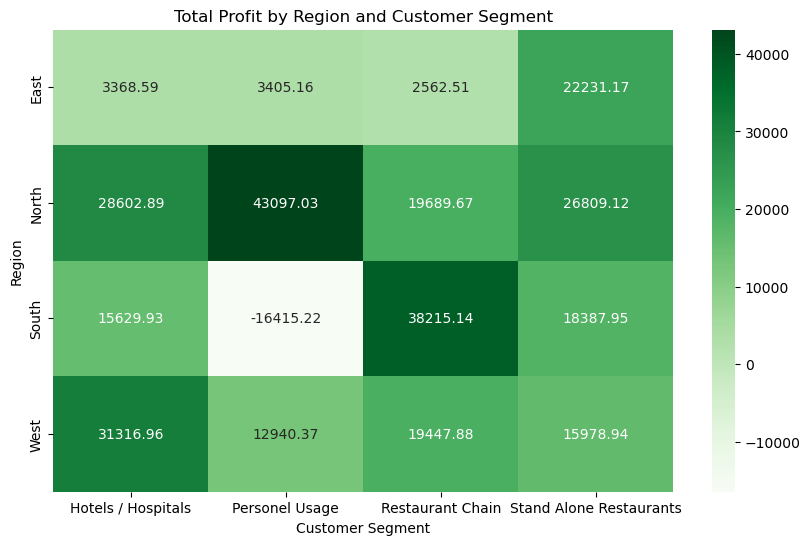

In [70]:
plt.figure(figsize=(10,6))

sns.heatmap(
    pivot_profit,
    annot=True,
    fmt='.2f',
    cmap='Greens'
)

plt.title('Total Profit by Region and Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Region')

plt.show()

The heatmap shows that the highest total profit is generated by the Personal Usage segment in the North region. The lowest total profit is recorded by the Personal Usage segment in the South region. This indicates that the profitability of the Personal Usage segment varies considerably across regions.

##### Order priority × Segment — Average_Profit

In [71]:
pivot_profit = pd.pivot_table(
    df,
    values='Profit',
    index='Order Priority',
    columns='Segment',
    aggfunc='mean'
)

pivot_profit

Segment,Hotels / Hospitals,Personel Usage,Restaurant Chain,Stand Alone Restaurants
Order Priority,,,,
Critical,33.522985,205.833999,159.499954,130.846864
High,71.857146,74.269434,101.629212,102.605337
Low,193.061172,198.582188,74.755397,539.635380
Medium,114.020302,62.607493,355.877580,337.169623
Not Specified,141.743803,-166.599710,143.493358,119.293259


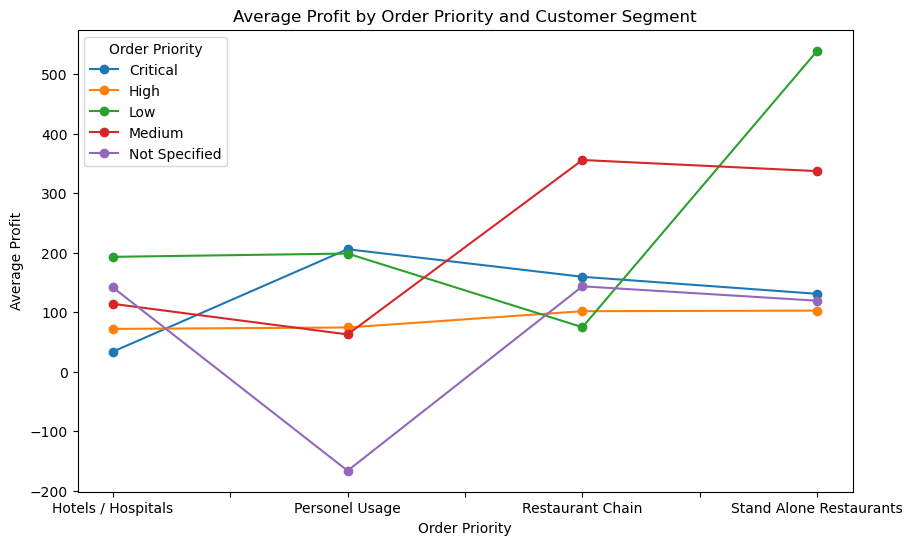

In [72]:
pivot_profit.T.plot(
    kind='line',
    marker='o',
    figsize=(10,6)
)

plt.title('Average Profit by Order Priority and Customer Segment')
plt.xlabel('Order Priority')
plt.ylabel('Average Profit')
plt.legend(title='Order Priority')

plt.show()

The Stand Alone Restaurants segment recorded the highest average profit, with the highest value occurring at the Low order priority level. In contrast, the Personel Usage segment recorded the lowest average profit, with its lowest value associated with the Not Specified order-priority level.

#### Multivariate Analysis

-Examines region, customer segment, product type,Product Sub-Category, sales, and profit together to understand more complex patterns in the dataset.

##### Region + Segment + Product Type → Profit

In [75]:
multi_profit = pd.pivot_table(
    df,
    values='Profit',
    index=['Region', 'Segment'],
    columns='Product Type',
    aggfunc='sum'
)

multi_profit

Product Type                    Canned Foods  Preserved Food  Processed Meat
Region Segment                                                              
East   Hotels / Hospitals       -2866.610096    -5217.326220    11452.529620
       Personel Usage            2927.396340       82.491600      395.267296
       Restaurant Chain           -21.915700     3873.700140    -1289.277812
       Stand Alone Restaurants  16072.031104     4018.205900     2140.937660
North  Hotels / Hospitals         -23.434156     -588.425580    29214.752600
       Personel Usage            6842.477994    10942.773070    25311.778795
       Restaurant Chain         17206.933050    14939.458368   -12456.719520
       Stand Alone Restaurants  12128.098530     7172.835210     7508.183254
South  Hotels / Hospitals       11847.104580     -370.427443     4153.248066
       Personel Usage          -17461.310980     1435.966960     -389.874456
       Restaurant Chain         16078.742980     -740.209720    22876.605020
       Stand Alone Restaurants  14183.473640     3118.290700     1086.182690
West   Hotels / Hospitals       16781.520406     8450.870600     6084.572488
       Personel Usage           -3674.570888     9561.263345     7053.680170
       Restaurant Chain          3146.073664     1349.164440    14952.639750
       Stand Alone Restaurants   9655.214480     7158.460340     -834.737156

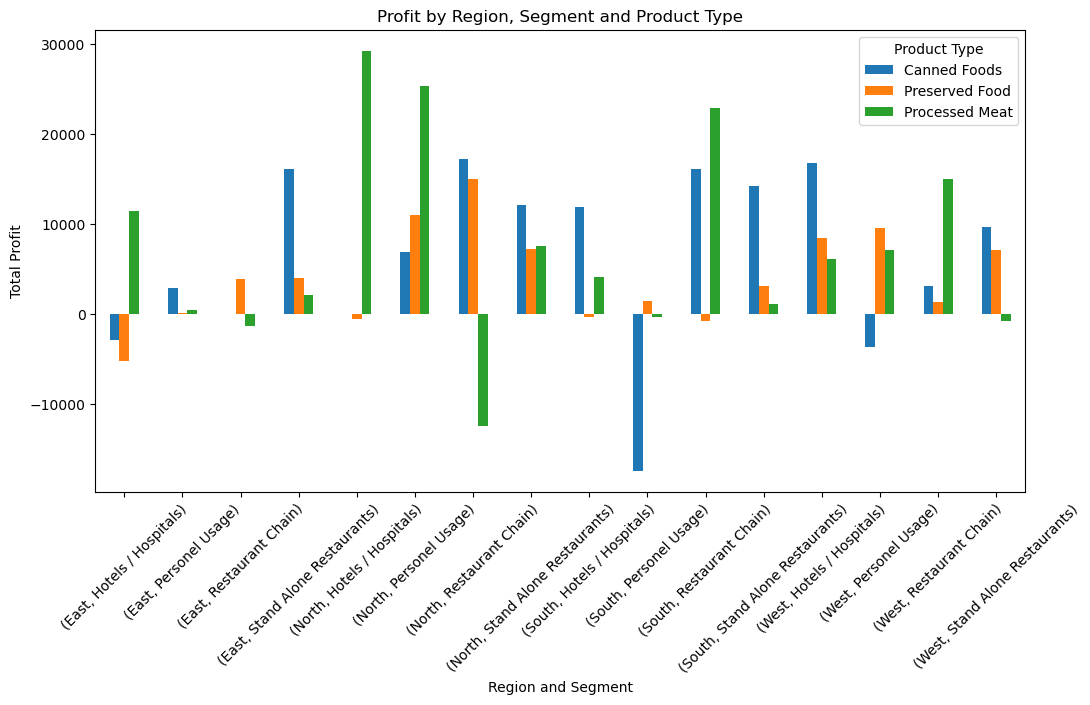

In [79]:
multi_profit.plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Profit by Region, Segment and Product Type')
plt.xlabel('Region and Segment')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.legend(title='Product Type')

plt.show()

Highest and Lowest profit

In [23]:
highest = multi_profit.stack().idxmax()
highest_profit = multi_profit.stack().max()

print("Highest Profit:")
print("Region:", highest[0])
print("Segment:", highest[1])
print("Product Type:", highest[2])
print("Profit:", highest_profit)

lowest = multi_profit.stack().idxmin()
lowest_profit = multi_profit.stack().min()

print("Lowest Profit:")
print("Region:", lowest[0])
print("Segment:", lowest[1])
print("Product Type:", lowest[2])
print("Profit:", lowest_profit)

Highest Profit:
Region: North
Segment: Hotels / Hospitals
Product Type: Processed Meat
Profit: 29214.752599999996
Lowest Profit:
Region: South
Segment: Personel Usage
Product Type: Canned Foods
Profit: -17461.310980000002


##### Region + Product Type+ Frieght Mode → Frieght Expenses

In [81]:
multi_frieght = pd.pivot_table(
    df,
    values='Freight Expenses',
    index=['Region', 'Product Type'],
    columns='Freight Mode',
    aggfunc='sum'
)

multi_frieght

Freight Mode           Delivery Truck  Express Air  Regular Air
Region Product Type                                            
East   Canned Foods            453.37        36.28       289.23
       Preserved Food         1178.19       112.95       426.74
       Processed Meat          212.10       180.51       840.31
North  Canned Foods            709.75       280.88      1255.43
       Preserved Food         3859.20       108.05       961.37
       Processed Meat          239.72       345.29      2931.46
South  Canned Foods            463.21       145.81       645.39
       Preserved Food         2372.44       105.87       404.11
       Processed Meat          225.95       327.68      1829.20
West   Canned Foods            585.59        72.18       992.08
       Preserved Food         4084.41       135.26       958.05
       Processed Meat          249.08       312.75      2641.32

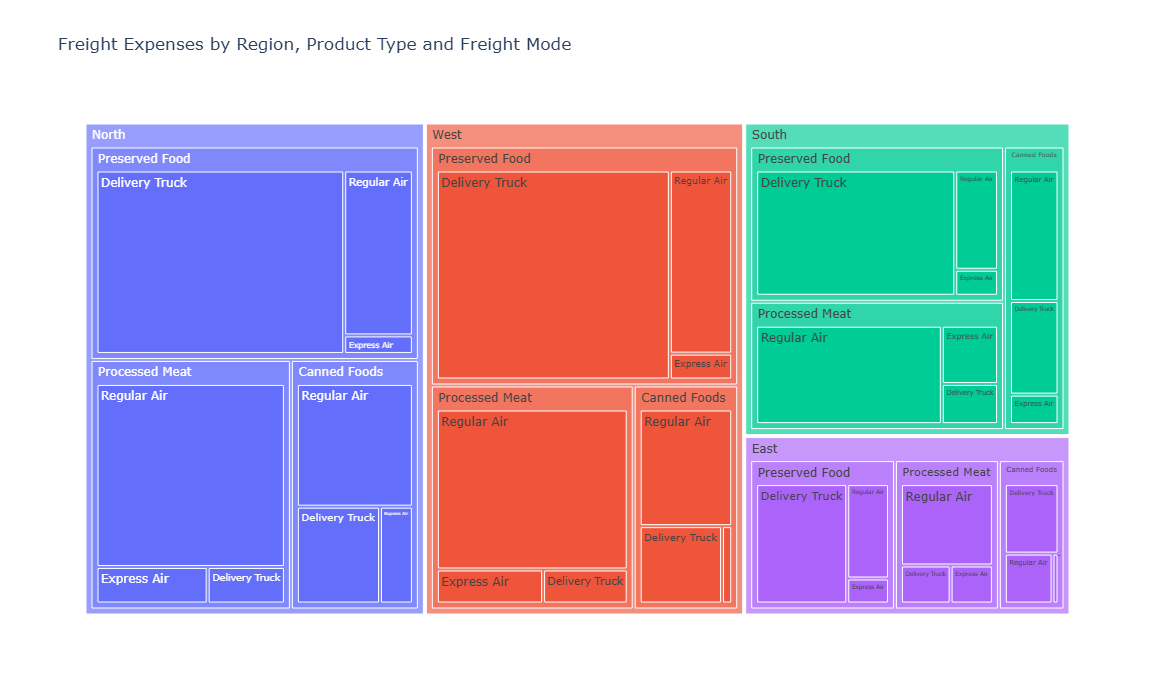

In [86]:
fig = px.treemap(
    df,
    path=['Region', 'Product Type', 'Freight Mode'],
    values='Freight Expenses',
    title='Freight Expenses by Region, Product Type and Freight Mode',
    width=900,
    height=700
)

fig.show()

Highest and Lowest frieght expenses

In [27]:
highest = multi_frieght.stack().idxmax()
highest_Expense = multi_frieght.stack().max()

print("Highest frieght expense:")
print("Region:", highest[0])
print("Product type:", highest[1])
print("Frieght mode:", highest[2])
print("Expense:", highest_Expense)

lowest = multi_frieght.stack().idxmin()
lowest_expense = multi_frieght.stack().min()

print("Lowest frieght expense:")
print("Region:", lowest[0])
print("Product type:", lowest[1])
print("Frieght mode:", lowest[2])
print("Expense:", lowest_expense)

Highest frieght expense:
Region: West
Product type: Preserved Food
Frieght mode: Delivery Truck
Expense: 4084.41
Lowest frieght expense:
Region: East
Product type: Canned Foods
Frieght mode: Express Air
Expense: 36.28


#### Correlation Analysis

Examine the relationships between Sales, Profit, QtyOrdered, Unit Price, Discount offered, Freight Expenses.

In [87]:
correlation = df[
    ['Sales', 'Profit', 'QtyOrdered',
     'Unit Price', 'Discount offered',
     'Freight Expenses']
].corr()

correlation

,Sales,Profit,QtyOrdered,Unit Price,Discount offered,Freight Expenses
Sales,1.000000,0.270358,0.318073,0.426958,-0.027153,0.260883
Profit,0.270358,1.000000,0.105965,-0.164284,-0.031247,0.002110
QtyOrdered,0.318073,0.105965,1.000000,-0.068376,-0.014581,-0.014659
Unit Price,0.426958,-0.164284,-0.068376,1.000000,-0.012236,0.207005
Discount offered,-0.027153,-0.031247,-0.014581,-0.012236,1.000000,-0.012414
Freight Expenses,0.260883,0.002110,-0.014659,0.207005,-0.012414,1.000000


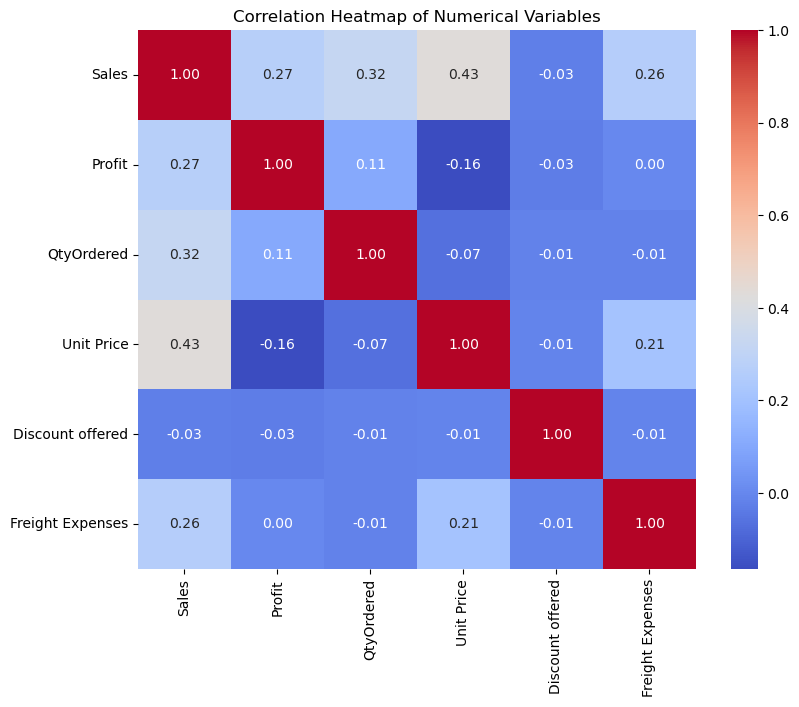

In [88]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

Observation: Sales and Unit Price have the strongest positive relationship (0.43) among the variables, followed by Quantity Ordered and Sales (0.32) and Sales and Profit (0.27). Profit and Unit Price have a weak negative relationship (−0.16). Discount Offered has almost no relationship with Sales (−0.03) or Profit (−0.03). Freight Expenses also show a weak positive relationship with Sales (0.26) but almost no relationship with Profit (0.002). Overall, most relationships in the dataset are weak, indicating that no single variable has a strong linear relationship with Profit. 

#### Monthly Sales Trend — Line Chart

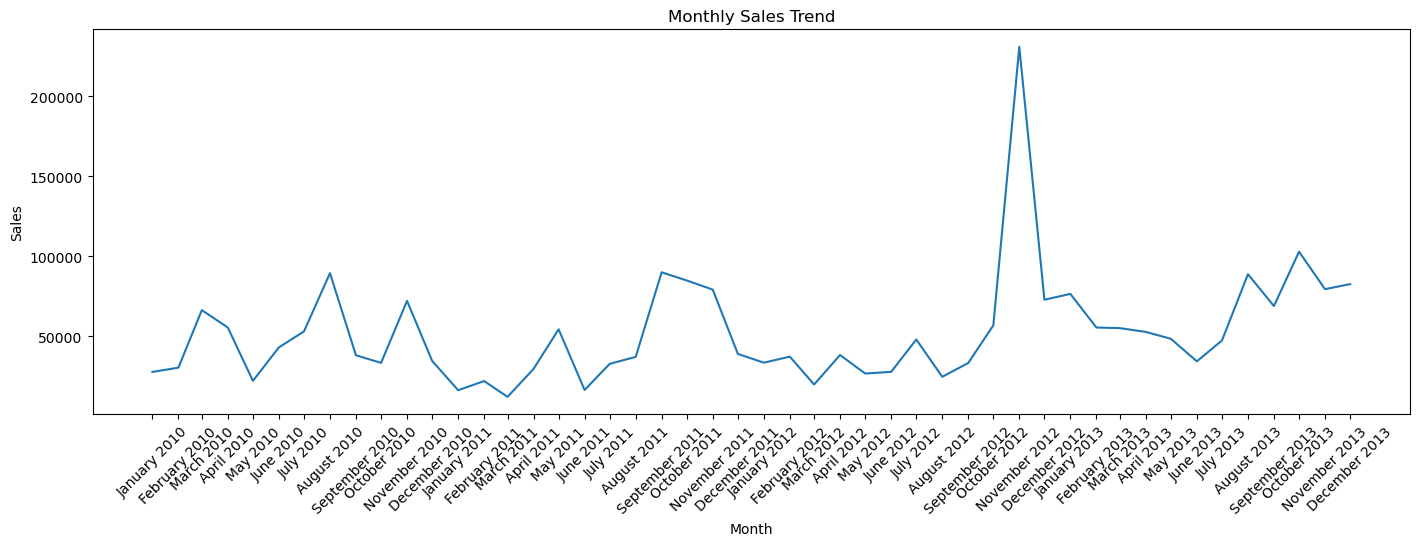

In [16]:
monthly_sales = df.groupby(
    df['Order Date'].dt.to_period('M')
)['Sales'].sum()
monthly_sales.index = monthly_sales.index.to_timestamp()
plt.figure(figsize=(17,5))
plt.plot(monthly_sales.index, monthly_sales.values)
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.xticks(monthly_sales.index,
    monthly_sales.index.strftime('%B %Y'),
    rotation=45)
plt.show()

The monthly sales trend shows that October 2012 recorded the highest sales during the period covered by the dataset. Sales varied across the different months and years, indicating changes in monthly sales performance over time.

#### Discount Offered — Histogram

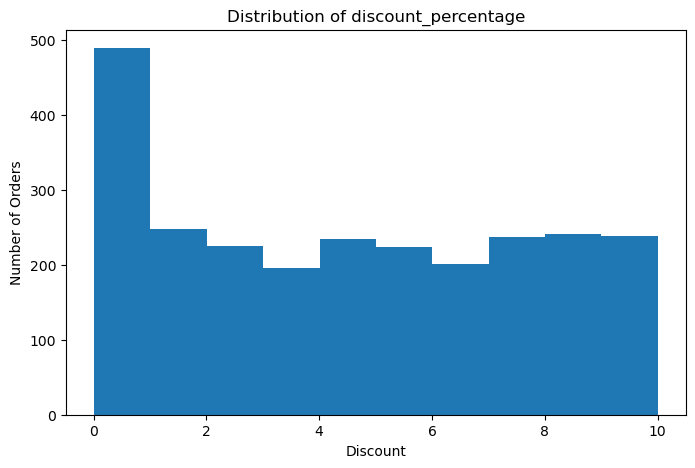

In [24]:
plt.figure(figsize=(8,5))
plt.hist(df['discount_percentage'], bins=10)
plt.title('Distribution of discount_percentage')
plt.xlabel('Discount')
plt.ylabel('Number of Orders')
plt.show()

The histogram shows that the highest number of orders, approximately 500, received discounts between 0% - 1%. The remaining orders are relatively evenly distributed across the other discount ranges, including 1%–2%, 2%–4%, 6%–8%, and 8%–10%.

#### Profit Distribution by Segment — Box Plot

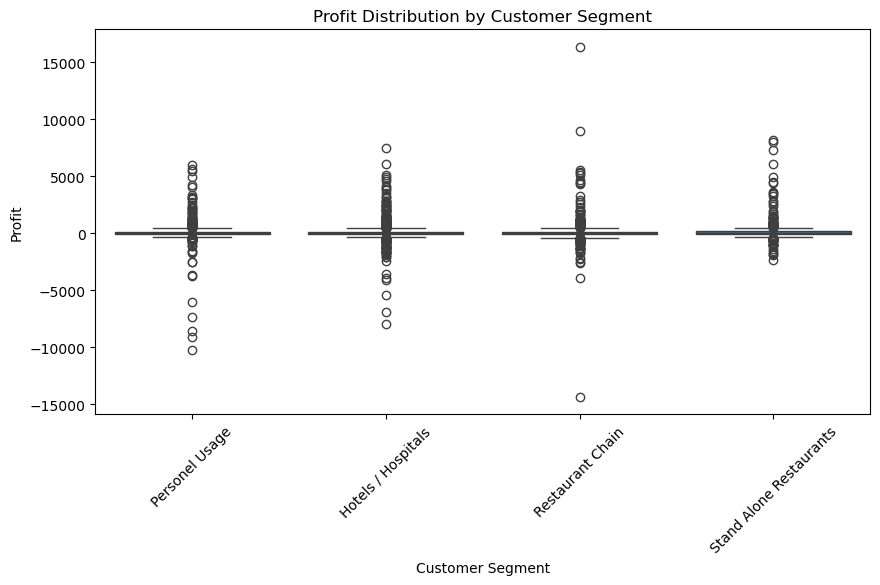

In [80]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='Segment', y='Profit')
plt.title('Profit Distribution by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Profit')
plt.xticks(rotation=45)
plt.show()

The box plot shows the distribution of Profit across different customer segments. The distributions contain several outliers, indicating that some orders have profit values that are considerably different from the typical profit values within their respective segments.

#### Profit Trend Over Time

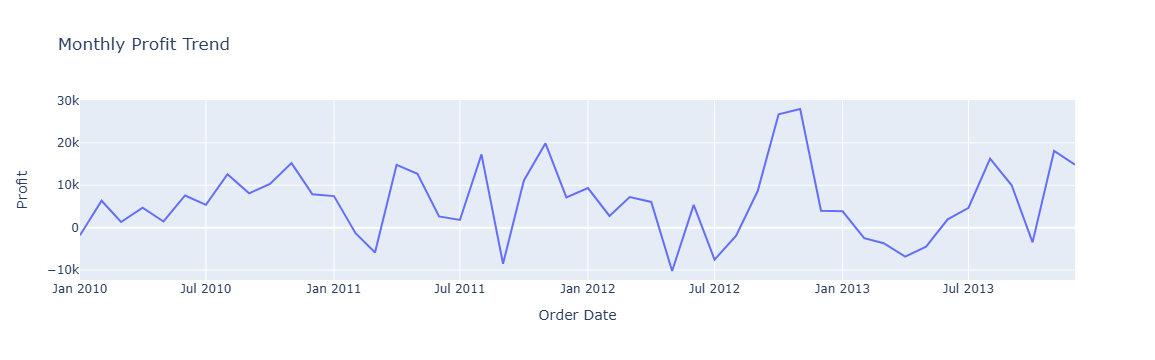

In [87]:
monthly_profit = df.groupby(
    df['Order Date'].dt.to_period('M')
)['Profit'].sum().reset_index()

monthly_profit['Order Date'] = monthly_profit['Order Date'].astype(str)

fig = px.line(
    monthly_profit,
    x='Order Date',
    y='Profit',
    title='Monthly Profit Trend'
)

fig.show()

The monthly profit trend shows variations in profitability across the months. November 2012 recorded the highest total profit of approximately 27.98K, making it the peak month in the dataset.
May 2012 recorded the lowest total profit of approximately −10.22K, indicating that the month experienced an overall loss based on the recorded orders.

### Key Business Insights

#### Regional sales performance

The North region recorded the highest total sales, followed closely by the West region, while the East region recorded the lowest sales. This shows that sales performance varies considerably across regions, indicating differences in regional market contribution.

#### Product profitability

Processed Meat generated the highest total profit, followed by Canned Foods and Preserved Food. However, when average profit per order is considered, Canned Foods had the highest average profit per order. This shows that total profitability and average profitability can provide different perspectives on product performance.

#### Customer segment profitability

The Stand Alone Restaurants segment recorded the highest profit margin at approximately 20.15%, while the Personel Usage segment had the lowest profit margin at approximately 6.44%. This indicates that some customer segments generate more profit relative to their sales than others.

#### Sales and profit relationship

The correlation analysis showed a weak positive relationship between Sales and Profit (approximately 0.27). This indicates that higher sales are generally associated with higher profit, but the relationship is not strong. Therefore, increasing sales alone does not necessarily guarantee higher profitability.

#### Multiple factors affect profitability

Profit showed only weak or very weak relationships with variables such as quantity ordered, discount offered, unit price, and freight expenses. This suggests that profitability is influenced by multiple factors rather than being strongly associated with one single numerical variable.

#### Difference between profitable and loss-making orders

The analysis of profitable and loss-making orders showed that their relationships between sales, profit, quantity, and freight expenses differ. In particular, some loss-making orders have relatively high sales but still generate negative profit. This indicates that high sales do not always translate into profitable orders, and costs such as freight expenses and other order-level factors need to be considered.

#### State-level profitability and outliers

State-level analysis revealed substantial differences in profit margins. Himachal Pradesh showed an unusually low profit margin, which was strongly influenced by an extreme loss-making order in the Processed Meat category. This order was treated as a potential outlier rather than being removed because there was insufficient evidence to confirm that it was an incorrect record.

#### Region and segment performance

The pivot table analysis showed that sales and profit vary across combinations of region and customer segment. For example, the Personal Usage segment in the North region recorded the highest total profit in the region–segment profit comparison, while the Personal Usage segment in the South region recorded the lowest.

#### Order priority and average profit

The analysis of order priority and customer segment showed that average profit varies across different combinations. Stand Alone Restaurants recorded their highest average profit at the Low order-priority level, while Personel Usage recorded the lowest average profit at the Not Specified priority level. This shows that average profitability differs across both customer segments and order-priority categories.

#### Time-based performance

The monthly trend analysis showed noticeable variation in profitability over time. November 2012 recorded the highest monthly profit at approximately 27.98K, while May 2012 recorded the lowest monthly profit at approximately −10.22K. This indicates that business profitability was not consistent across all months and that certain periods performed considerably better or worse than others.

#### Freight expense patterns

The multivariate analysis showed that freight expenses vary across regions, product types, and freight modes. This indicates that shipping-related costs are not uniform across all orders and that certain combinations of region, product type, and freight mode may require closer monitoring.

#### Profit distribution and unusual orders

The box plot and violin plot showed considerable variation in individual order-level profits, including several outliers across customer segments. The violin plots also showed that many product-type orders have profit values concentrated around zero, while a smaller number of orders have much higher profits or losses. This highlights the importance of examining individual orders in addition to aggregated business performance.